# Analise Exploratoria - Dengue e Clima
**Fontes:** InfoDengue (casos semanais) e Open-Meteo (clima diario), armazenadas no PostgreSQL (`vw_base_modelo`).

**Perguntas:** (1) como a dengue varia entre cidades e anos? (2) ha sazonalidade? (3) clima se relaciona com a incidencia?

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from config import get_engine, LIMIAR_SURTO, HORIZONTE, ANO_TESTE
sns.set_theme(style="whitegrid")
eng = get_engine()
df = pd.read_sql('select * from vw_base_modelo order by geocode, se', eng, parse_dates=['data_ini'])
print(df.shape)
df.head()

(2496, 18)


,geocode,municipio,uf,se,data_ini,ano,semana,casos,casos_est,populacao,inc100k,nivel_alerta,rt,temp_media,temp_max,temp_min,precip_mm,umid_media
0,1302603,Manaus,AM,202101,2021-01-03,2021,1,65,65.0,2219580,2.9285,1,2.3249,26.085714,30.2,23.5,66.6,86.571429
1,1302603,Manaus,AM,202102,2021-01-10,2021,2,57,57.0,2219580,2.5681,1,1.9025,26.042857,29.9,22.9,28.2,86.142857
2,1302603,Manaus,AM,202103,2021-01-17,2021,3,83,83.0,2219580,3.7394,3,1.7606,25.557143,30.7,23.1,81.3,87.857143
3,1302603,Manaus,AM,202104,2021-01-24,2021,4,65,65.0,2219580,2.9285,1,1.0406,25.742857,29.0,23.1,34.3,87.571429
4,1302603,Manaus,AM,202105,2021-01-31,2021,5,122,122.0,2219580,5.4965,1,1.6769,26.814286,30.6,23.8,45.0,85.571429


## 1. Qualidade dos dados

In [2]:
print(df.isna().sum()[lambda s: s>0])
print('duplicados (municipio, semana):', df.duplicated(['geocode','se']).sum())
df.describe().T[['count','mean','min','50%','max']].round(2)

Series([], dtype: int64)
duplicados (municipio, semana): 0


,count,mean,min,50%,max
geocode,2496.0,3519583.75,1302603.0,3407029.5,5300108.0
se,2496.0,202276.5,202101.0,202276.5,202452.0
data_ini,2496,2022-12-28 12:00:00,2021-01-03 00:00:00,2022-12-28 12:00:00,2024-12-22 00:00:00
ano,2496.0,2022.5,2021.0,2022.5,2024.0
semana,2496.0,26.5,1.0,26.5,52.0
casos,2496.0,1289.277644,0.0,223.5,85389.0
casos_est,2496.0,1289.277644,0.0,223.5,85389.0
populacao,2496.0,3252724.625801,906092.0,2306129.0,12325232.0
inc100k,2496.0,38.920878,0.0,9.40625,1265.653
nivel_alerta,2496.0,1.926282,1.0,1.0,4.0


## 2. Incidencia por municipio e ano

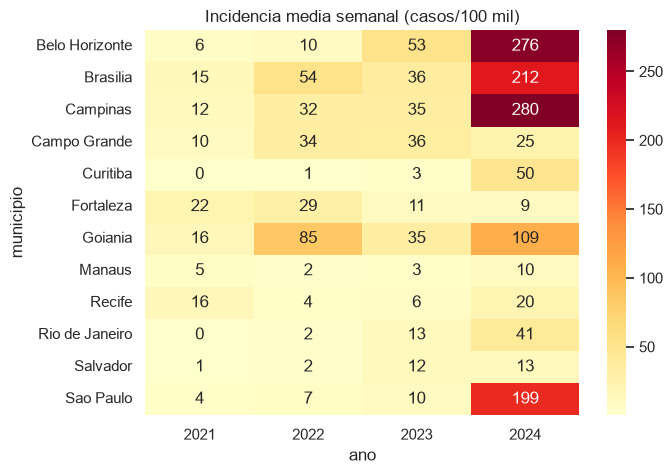

In [3]:
pt = df.pivot_table(index='municipio', columns='ano', values='inc100k', aggfunc='mean').round(1)
plt.figure(figsize=(7,5)); sns.heatmap(pt, annot=True, fmt='.0f', cmap='YlOrRd'); plt.title('Incidencia media semanal (casos/100 mil)'); plt.show()

**Leitura:** 2024 foi um ano epidemico, com incidencia muito acima de 2021-2023, principalmente no Sudeste e Centro-Oeste. Isso cria um *shift* de distribuicao entre treino e teste, importante para interpretar as metricas.

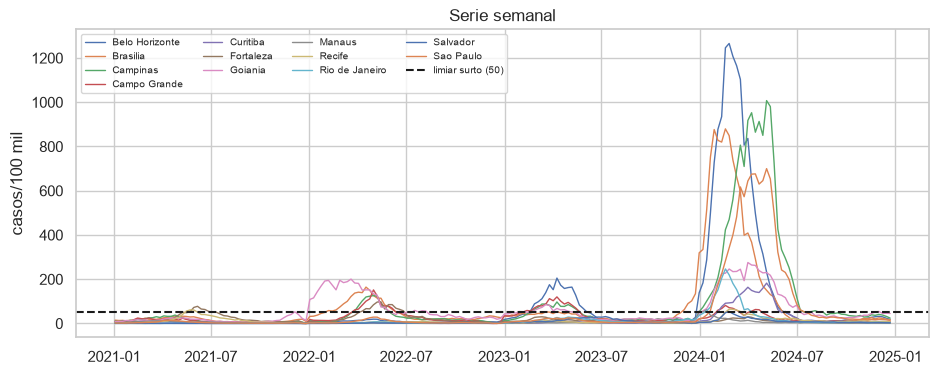

In [4]:
fig, ax = plt.subplots(figsize=(11,4))
for m, g in df.groupby('municipio'):
    ax.plot(g['data_ini'], g['inc100k'], lw=1, label=m)
ax.axhline(LIMIAR_SURTO, color='k', ls='--', label=f'limiar surto ({LIMIAR_SURTO:.0f})')
ax.set_ylabel('casos/100 mil'); ax.set_title('Serie semanal'); ax.legend(ncol=4, fontsize=7); plt.show()

## 3. Sazonalidade

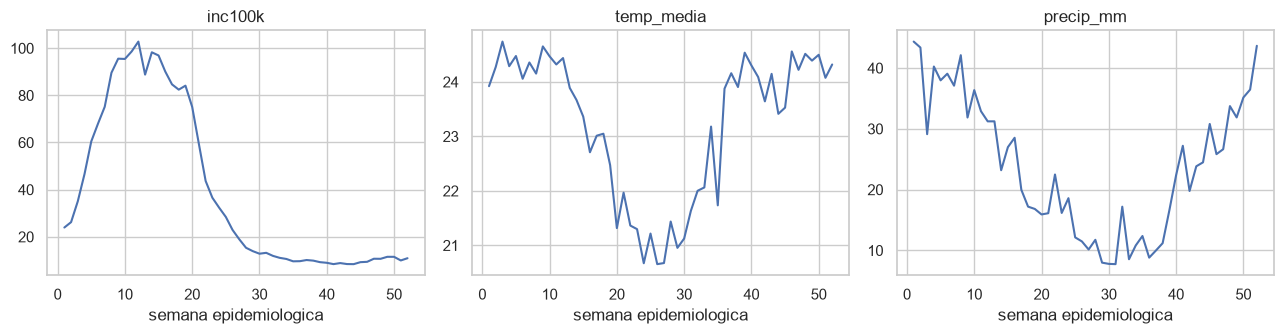

In [5]:
s = df.groupby(['semana'])[['inc100k','temp_media','precip_mm']].mean()
fig, ax = plt.subplots(1,3, figsize=(13,3.5))
for a, c in zip(ax, s.columns): s[c].plot(ax=a, title=c); a.set_xlabel('semana epidemiologica')
plt.tight_layout(); plt.show()

A incidencia e maxima entre as semanas ~9 e 15 (fim do verao), depois dos picos de chuva (semana 1) e temperatura (semana 3): ha defasagem de varias semanas. Por isso o modelo usa **defasagens e acumulados** de clima.

## 4. Clima x incidencia (correlacao com defasagem)

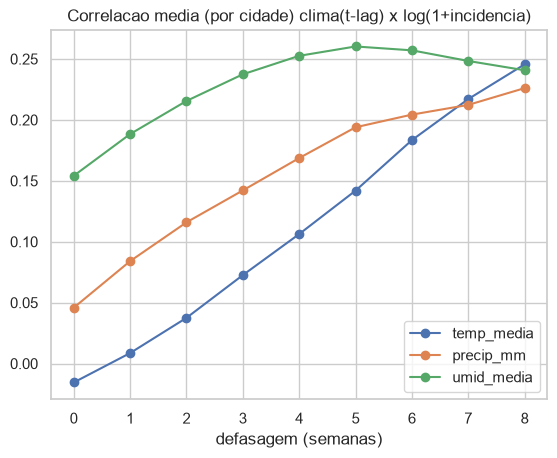

,temp_media,precip_mm,umid_media
defasagem (semanas),,,
0,-0.02,0.05,0.15
1,0.01,0.08,0.19
2,0.04,0.12,0.22
3,0.07,0.14,0.24
4,0.11,0.17,0.25
5,0.14,0.19,0.26
6,0.18,0.20,0.26
7,0.22,0.21,0.25
8,0.25,0.23,0.24


In [6]:
d = df.sort_values(['geocode','se']).copy()
res = {}
for var in ['temp_media','precip_mm','umid_media']:
    res[var] = [d.groupby('geocode').apply(lambda g: g[var].shift(l).corr(g['inc100k'].apply(np.log1p))).mean() for l in range(0, 9)]
res = pd.DataFrame(res, index=pd.Index(range(0,9), name='defasagem (semanas)'))
res.plot(marker='o', title='Correlacao media (por cidade) clima(t-lag) x log(1+incidencia)'); plt.show()
res.round(2)

## 5. Alvo da modelagem

In [7]:
print(f'Alvo: incidencia daqui a {HORIZONTE} semanas >= {LIMIAR_SURTO:.0f}/100 mil')
print((df['inc100k']>=LIMIAR_SURTO).groupby(df['ano']).mean().round(3).rename('% semanas em surto'))

Alvo: incidencia daqui a 4 semanas >= 50/100 mil
ano
2021    0.022
2022    0.130
2023    0.107
2024    0.296
Name: % semanas em surto, dtype: float64


**Conclusoes:** dados consistentes; forte heterogeneidade entre cidades e anos; a correlacao clima x incidencia e fraca na semana corrente (~0) e cresce com a defasagem (ate ~0,25 em 8 semanas), confirmando o efeito defasado; classes desbalanceadas (surto e minoria no treino) -> `class_weight='balanced'` e metricas alem de Accuracy (F1, recall, ROC-AUC).